# DSC212 Research Assignment: Modularity on the Karate Club Graph

**Name:** Prince Punjabi  
**Roll Number:** IMS25153  
**Course:** DSC212 — Mathematical Foundations for Data Science (Graph Theory Module)  
**Institute:** IISER Thiruvananthapuram  

---

## 1. Introduction & Mathematical Background

In the early 1970s, anthropologist Wayne W. Zachary observed social interactions among **34 members** of a university karate club over two years, recording **78 frequent interaction edges** between them (Zachary, 1977). Following a dispute over fees between the club instructor (**Mr. Hi**, Node 0) and the club administrator (**Officer**, Node 33), the club split into two rival factions.

The goal of this assignment is to uncover the club's community structure purely from the graph topology using **recursive spectral modularity partitioning**, based on **Newman (2006)**, *"Modularity and community structure in networks,"* PNAS 103(23):8577–8582.

### Key Mathematical Ideas
1. **Why Modularity?** Simply minimizing the number of cut edges can isolate single low-degree vertices rather than finding meaningful groups. Modularity $Q$ instead compares the observed fraction of within-community edges against the expected fraction under a degree-preserving random null model.
2. **Modularity Matrix ($B$):** For an undirected, unweighted graph $G = (V, E)$ with adjacency matrix $A \in \{0,1\}^{n \times n}$, degree vector $k_i = \sum_j A_{ij}$, and $m = |E|$ edges ($\sum_i k_i = 2m$),
   $$B = A - \frac{k k^\top}{2m}, \qquad B_{ij} = A_{ij} - \frac{k_i k_j}{2m}.$$
   Since $B$ is real and symmetric, all its eigenvalues are real and its eigenvectors form an orthonormal basis. Moreover, $B\mathbf{1} = \mathbf{0}$, so the trivial single-community partition has $Q = 0$.
3. **Spectral Relaxation (Rayleigh–Ritz):** For a bipartition $s \in \{-1, +1\}^n$, modularity is $Q = \frac{1}{4m} s^\top B s$. Relaxing $s$ to a continuous unit vector $\|s\|_2 = 1$, the Rayleigh–Ritz theorem guarantees that $s^\top B s$ is maximized by the **leading eigenvector** $u_1$ corresponding to the largest eigenvalue $\lambda_1$. Thresholding by the sign of $u_1$ ($s_i = +1$ if $(u_1)_i > 0$, else $-1$) yields a discrete bipartition.
4. **Recursive Bisection & Stopping Criterion:** To detect more than two communities, we recursively attempt to split each existing community $C \subseteq V$ using Newman's generalized modularity matrix restricted to $C$:
   $$B^{(C)}_{ij} = B_{ij} - \delta_{ij} \sum_{l \in C} B_{il}, \quad i, j \in C.$$
   The diagonal row-sum correction ensures that the exact change in global modularity from splitting $C$ is $\Delta Q = \frac{1}{4m} s^\top B^{(C)} s$. If the leading eigenvalue $\lambda_1^{(C)} \le 0$ (or the resulting discrete split yields $\Delta Q \le 0$), no further split can improve modularity, so the community is indivisible and recursion stops.


## 2. Setup and Initial Graph Exploration

We import `numpy`, `networkx`, and `matplotlib.pyplot`, load Zachary's Karate Club graph, and verify its basic structural properties. Note that we pass `weight=None` when constructing the adjacency matrix $A$ so that it is strictly binary ($A_{ij} \in \{0, 1\}$), ensuring $\sum_i k_i = 2m = 156$.


Number of nodes (n): 34
Number of edges (m): 78
Sum of degrees = 156 (2m = 156)
Is B symmetric? True
Max |B @ 1| (should be ~0): 8.88e-16


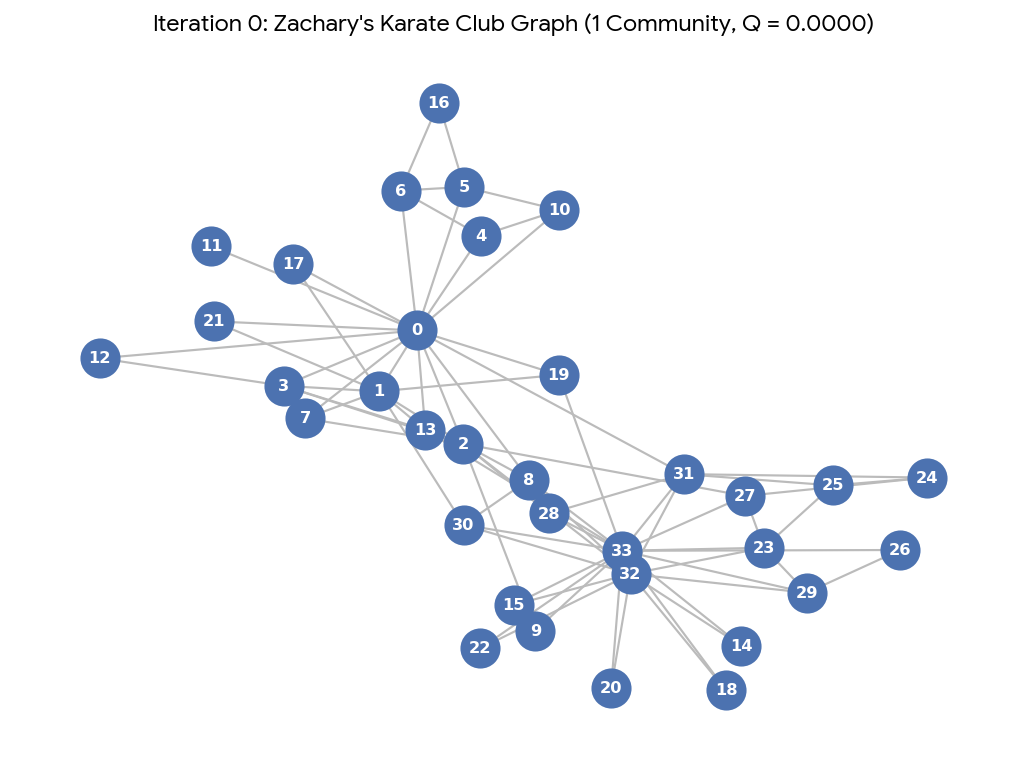

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

# Load Zachary's Karate Club graph
G = nx.karate_club_graph()
nodes = list(G.nodes())
n = G.number_of_nodes()
m = G.number_of_edges()

print(f"Number of nodes (n): {n}")
print(f"Number of edges (m): {m}")

# Construct binary adjacency matrix A, degree vector k, and modularity matrix B
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
k = A.sum(axis=1)
B = A - np.outer(k, k) / (2 * m)

# Verify key mathematical properties of B
print(f"Sum of degrees = {int(k.sum())} (2m = {2 * m})")
print(f"Is B symmetric? {np.allclose(B, B.T)}")
print(f"Max |B @ 1| (should be ~0): {np.max(np.abs(B @ np.ones(n))):.2e}")

# Fix a consistent spring layout for all visualizations across iterations
pos = nx.spring_layout(G, seed=42)

# Visualize the initial unpartitioned graph (Iteration 0)
plt.figure(figsize=(8, 6))
nx.draw_networkx(
    G, pos,
    node_color="#4C72B0",
    node_size=450,
    font_color="white",
    font_weight="bold",
    font_size=9,
    edge_color="#BBBBBB",
    width=1.2
)
plt.title("Iteration 0: Zachary's Karate Club Graph (1 Community, Q = 0.0000)", fontsize=13, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

## 3. Task 1: Recursive Spectral Modularity Partitioning

We implement Newman's (2006) recursive spectral bipartition algorithm from scratch:
1. Start with the full vertex set $V = \{0, 1, \dots, 33\}$ as a single community.
2. For each candidate community $C$, form the generalized restricted modularity matrix $B^{(C)}$.
3. Compute its leading eigenpair $(\lambda_1^{(C)}, u_1^{(C)})$ via `np.linalg.eigh` (which exploits real symmetry and returns eigenvalues in ascending order).
4. If $\lambda_1^{(C)} > 0$, threshold $u_1^{(C)}$ by sign into $C^+$ and $C^-$, and check that the discrete modularity gain $\Delta Q = \frac{1}{4m} s^\top B^{(C)} s > 0$.
5. Record the full partition state after every accepted split so we can visualize the graph and track node metrics across iterations.


In [2]:
def compute_modularity(communities, B, m):
    """Compute global modularity Q for a list of communities."""
    Q = 0.0
    for comm in communities:
        idx = list(comm)
        Q += B[np.ix_(idx, idx)].sum()
    return Q / (2 * m)


def spectral_bipartition(community, B, m, tol=1e-10):
    """
    Attempt a single spectral bipartition of a candidate community C
    using Newman's (2006) generalized modularity matrix B^(C).
    Returns (can_split, C_pos, C_neg, lam1, delta_Q).
    """
    if len(community) <= 1:
        return False, community, [], 0.0, 0.0

    # Restrict global modularity matrix B to nodes in C
    subB = B[np.ix_(community, community)].copy()
    # Subtract row sums from diagonal (Newman's generalized modularity matrix)
    Bg = subB - np.diag(subB.sum(axis=1))

    # Symmetric eigendecomposition (eigenvalues sorted in ascending order)
    eigvals, eigvecs = np.linalg.eigh(Bg)
    lam1 = eigvals[-1]
    u1 = eigvecs[:, -1]

    # Stopping criterion: leading eigenvalue must be strictly positive
    if lam1 <= tol:
        return False, community, [], lam1, 0.0

    # Threshold leading eigenvector by sign into two sub-communities
    s = np.where(u1 > 0, 1, -1)
    c_pos = [community[i] for i in range(len(community)) if s[i] == 1]
    c_neg = [community[i] for i in range(len(community)) if s[i] == -1]

    # Verify non-trivial split and positive discrete modularity gain
    delta_Q = float((s @ Bg @ s) / (4 * m))
    if len(c_pos) == 0 or len(c_neg) == 0 or delta_Q <= tol:
        return False, community, [], lam1, delta_Q

    return True, c_pos, c_neg, lam1, delta_Q


def recursive_spectral_partitioning(nodes, B, m):
    """
    Recursively bisect communities until no further split increases modularity.
    Records the partition state and metadata after each split.
    """
    current_communities = [list(nodes)]
    iteration_history = [{
        "iteration": 0,
        "communities": [list(nodes)],
        "modularity": compute_modularity([nodes], B, m),
        "split_info": "Initial graph (no split)"
    }]

    split_count = 0
    idx = 0

    while idx < len(current_communities):
        comm = current_communities[idx]
        can_split, c_pos, c_neg, lam1, dQ = spectral_bipartition(comm, B, m)

        if can_split:
            split_count += 1
            # Replace the split community with its two child communities
            current_communities = (
                current_communities[:idx]
                + [c_pos, c_neg]
                + current_communities[idx + 1:]
            )
            Q_now = compute_modularity(current_communities, B, m)
            info = (
                f"Split community of size {len(comm)} -> sizes {len(c_pos)} & {len(c_neg)} "
                f"(lambda_1 = {lam1:.4f}, delta_Q = +{dQ:.4f}, Q = {Q_now:.4f})"
            )
            iteration_history.append({
                "iteration": split_count,
                "communities": [list(c) for c in current_communities],
                "modularity": Q_now,
                "split_info": info
            })
            # Do not increment idx; re-check the newly formed left child (recursive DFS)
        else:
            idx += 1

    return iteration_history


# Run recursive spectral modularity partitioning
history = recursive_spectral_partitioning(nodes, B, m)

print("=== Recursive Spectral Modularity Partitioning Log ===")
for step in history:
    print(f"Iteration {step['iteration']}: {len(step['communities'])} communities | Q = {step['modularity']:.4f}")
    print(f"   -> {step['split_info']}")

print("\nFinal Detected Communities:")
for i, comm in enumerate(history[-1]["communities"], start=1):
    print(f"  Community {i} (size {len(comm):2d}): {sorted(comm)}")

# Compare Iteration 1 (first bipartition) with Zachary's ground-truth split
gt_mr_hi = {node for node, data in G.nodes(data=True) if data["club"] == "Mr. Hi"}
gt_officer = {node for node, data in G.nodes(data=True) if data["club"] == "Officer"}

c1_set, c2_set = set(history[1]["communities"][0]), set(history[1]["communities"][1])
# Align labels for accuracy comparison
acc1 = (len(c1_set & gt_mr_hi) + len(c2_set & gt_officer)) / n
acc2 = (len(c1_set & gt_officer) + len(c2_set & gt_mr_hi)) / n
best_acc = max(acc1, acc2)
print(f"\nFirst Split Accuracy vs. Zachary's Ground Truth: {best_acc * 100:.2f}% ({int(round(best_acc * n))}/{n} nodes)")

=== Recursive Spectral Modularity Partitioning Log ===
Iteration 0: 1 communities | Q = -0.0000
   -> Initial graph (no split)
Iteration 1: 2 communities | Q = 0.3715
   -> Split community of size 34 -> sizes 16 & 18 (lambda_1 = 4.9771, delta_Q = +0.3715, Q = 0.3715)
Iteration 2: 3 communities | Q = 0.3727
   -> Split community of size 16 -> sizes 7 & 9 (lambda_1 = 1.1785, delta_Q = +0.0012, Q = 0.3727)
Iteration 3: 4 communities | Q = 0.3934
   -> Split community of size 18 -> sizes 12 & 6 (lambda_1 = 0.8594, delta_Q = +0.0207, Q = 0.3934)

Final Detected Communities:
  Community 1 (size  7): [0, 4, 5, 6, 10, 11, 16]
  Community 2 (size  9): [1, 2, 3, 7, 12, 13, 17, 19, 21]
  Community 3 (size 12): [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
  Community 4 (size  6): [23, 24, 25, 27, 28, 31]

First Split Accuracy vs. Zachary's Ground Truth: 97.06% (33/34 nodes)


## 4. Task 2: Visualizing Community Splits Across Iterations

Below we plot the Karate Club network after each split using the same fixed spring layout (`seed=42`). Each community is assigned a distinct color, and inter-community edges are drawn as dashed light-grey lines so that both the original topology and the community boundaries remain clearly visible. We also include a direct comparison between **Iteration 1** and **Zachary's ground-truth split**.


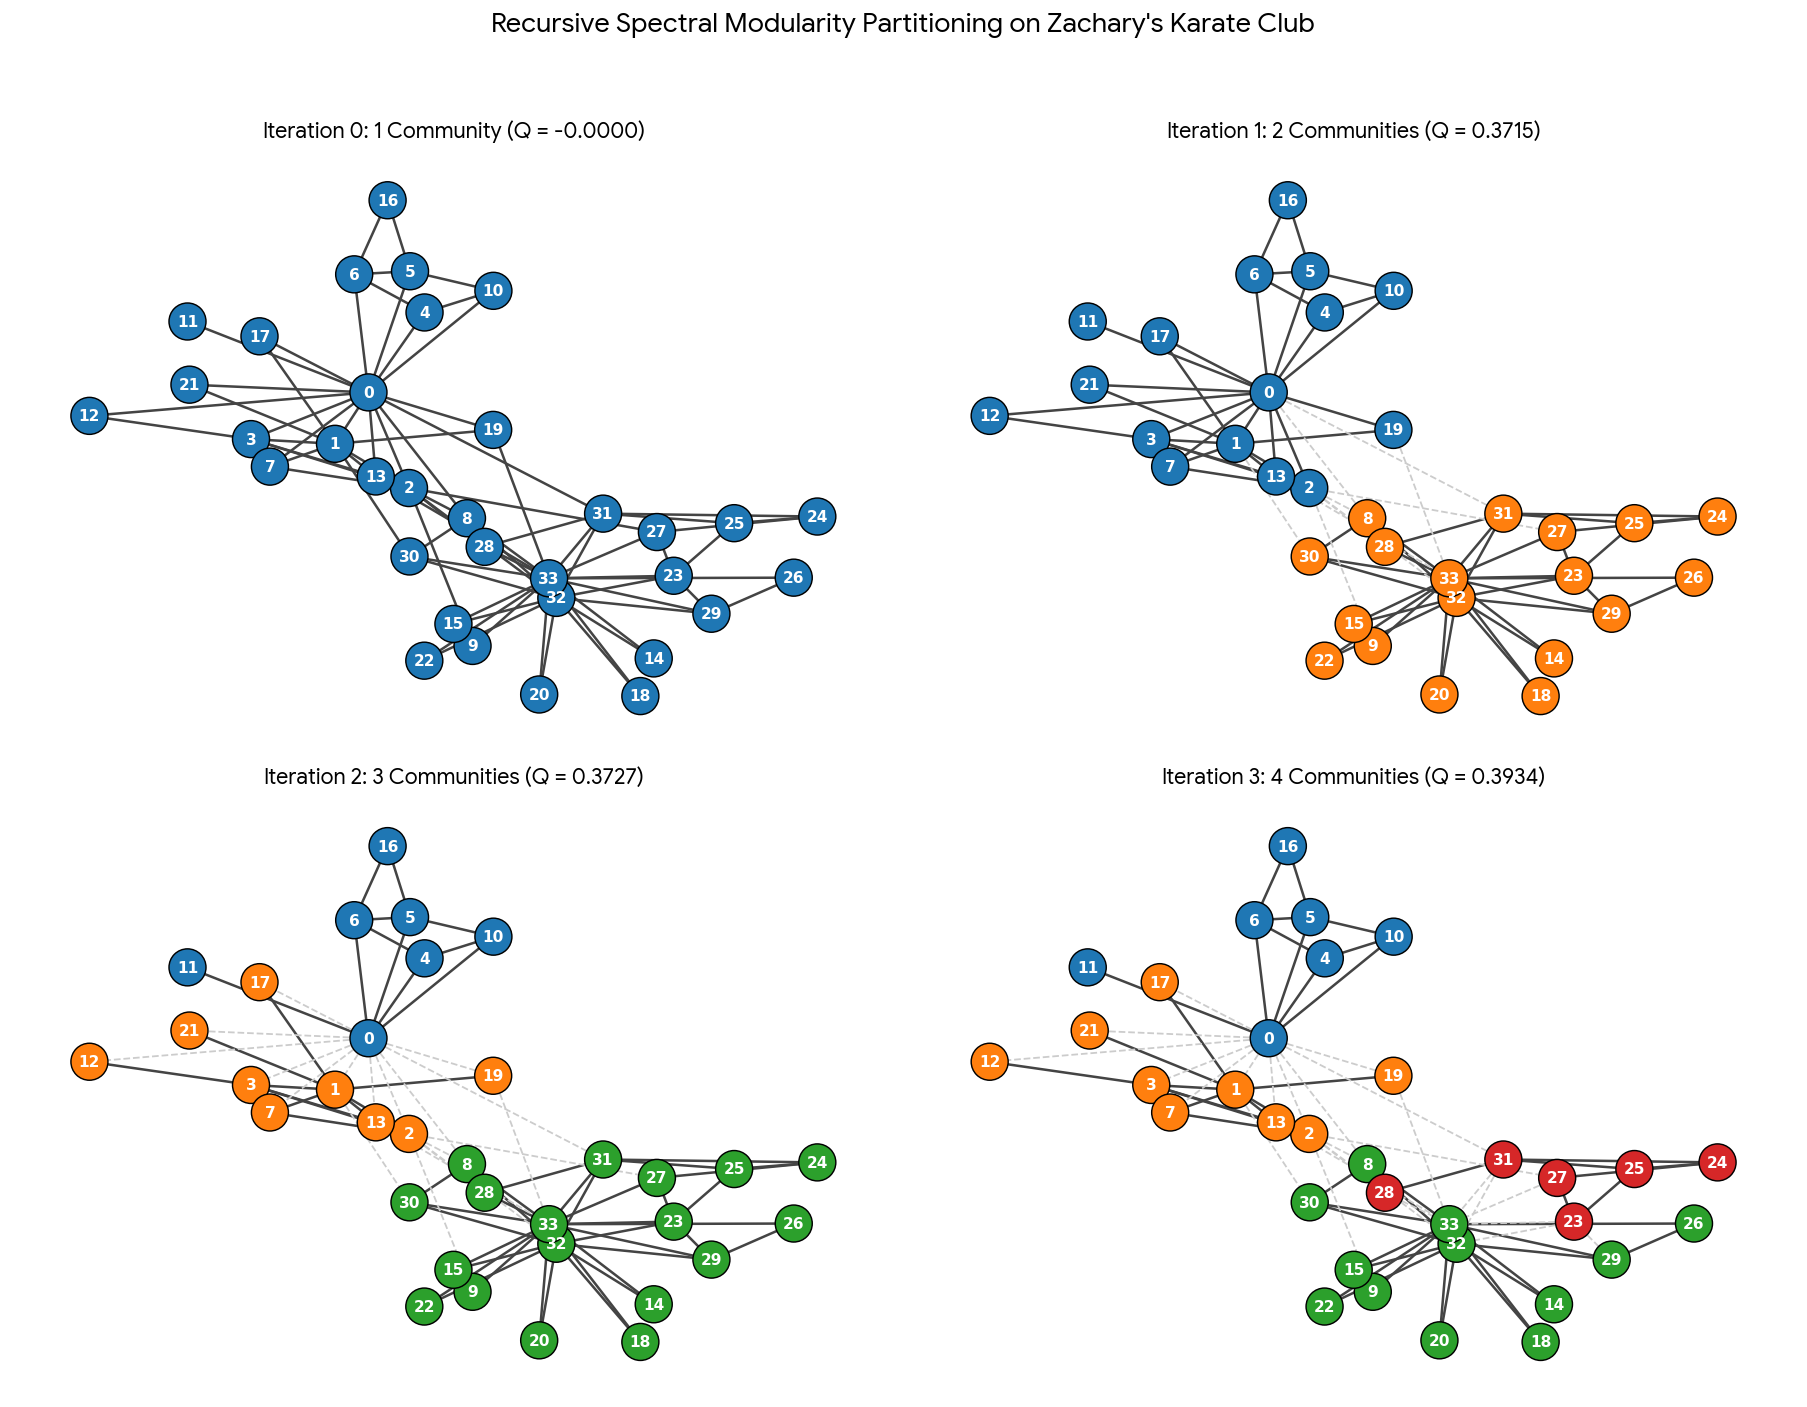

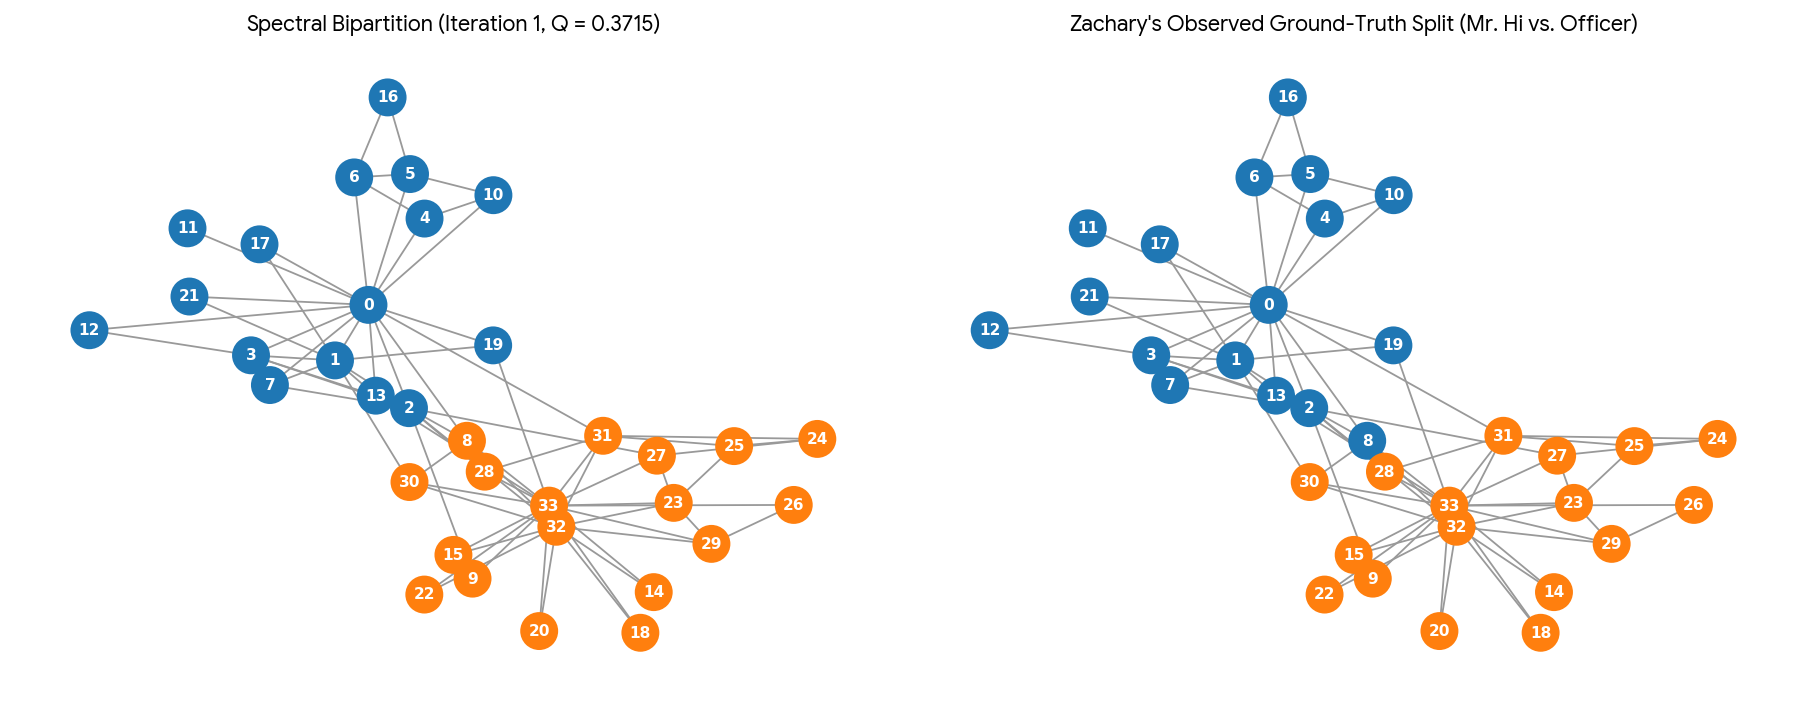

In [3]:
palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]

def get_node_to_comm(communities):
    mapping = {}
    for cid, comm in enumerate(communities):
        for node in comm:
            mapping[node] = cid
    return mapping

# Plot all iterations in a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()

for ax, step in zip(axes, history):
    it = step["iteration"]
    comms = step["communities"]
    Q_val = step["modularity"]
    node_to_comm = get_node_to_comm(comms)

    node_colors = [palette[node_to_comm[u] % len(palette)] for u in G.nodes()]
    intra_edges = [(u, v) for u, v in G.edges() if node_to_comm[u] == node_to_comm[v]]
    inter_edges = [(u, v) for u, v in G.edges() if node_to_comm[u] != node_to_comm[v]]

    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors, node_size=420, edgecolors="black", linewidths=0.8)
    nx.draw_networkx_labels(G, pos, ax=ax, font_color="white", font_weight="bold", font_size=8.5)
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=intra_edges, edge_color="#444444", width=1.4)
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=inter_edges, edge_color="#CCCCCC", style="dashed", width=1.0)

    ax.set_title(
        f"Iteration {it}: {len(comms)} Communit{'y' if len(comms)==1 else 'ies'} (Q = {Q_val:.4f})",
        fontsize=12, fontweight="bold"
    )
    ax.axis("off")

plt.suptitle("Recursive Spectral Modularity Partitioning on Zachary's Karate Club", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Side-by-side comparison: Iteration 1 Spectral Split vs Ground Truth
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: Iteration 1
node_to_comm_1 = get_node_to_comm(history[1]["communities"])
colors_1 = [palette[node_to_comm_1[u]] for u in G.nodes()]
nx.draw_networkx(G, pos, ax=ax1, node_color=colors_1, node_size=400, font_color="white", font_weight="bold", font_size=8.5, edge_color="#999999")
ax1.set_title(f"Spectral Bipartition (Iteration 1, Q = {history[1]['modularity']:.4f})", fontsize=12, fontweight="bold")
ax1.axis("off")

# Right: Ground Truth
gt_colors = [palette[0] if G.nodes[u]["club"] == "Mr. Hi" else palette[1] for u in G.nodes()]
nx.draw_networkx(G, pos, ax=ax2, node_color=gt_colors, node_size=400, font_color="white", font_weight="bold", font_size=8.5, edge_color="#999999")
ax2.set_title("Zachary's Observed Ground-Truth Split (Mr. Hi vs. Officer)", fontsize=12, fontweight="bold")
ax2.axis("off")

plt.tight_layout()
plt.show()

## 5. Task 3: Computing Node Metrics After Each Split

To observe how community splits reshape node importance and local cohesion, at each iteration we construct the **partitioned graph** $G^{(t)}$ by removing all inter-community edges (retaining only edges whose endpoints belong to the same community at iteration $t$). We then compute the four required NetworkX metrics for every node:
- **Degree Centrality:** `nx.degree_centrality(G_t)`
- **Betweenness Centrality:** `nx.betweenness_centrality(G_t)`
- **Closeness Centrality:** `nx.closeness_centrality(G_t)`
- **Clustering Coefficient:** `nx.clustering(G_t)`

All values are stored in dictionaries keyed by iteration number.


In [4]:
# Dictionaries keyed by iteration number -> {node_id: metric_value}
degree_hist = {}
betweenness_hist = {}
closeness_hist = {}
clustering_hist = {}

for step in history:
    it = step["iteration"]
    node_to_comm = get_node_to_comm(step["communities"])

    # Build partitioned graph for this iteration by keeping only intra-community edges
    G_iter = nx.Graph()
    G_iter.add_nodes_from(G.nodes())
    for u, v in G.edges():
        if node_to_comm[u] == node_to_comm[v]:
            G_iter.add_edge(u, v)

    degree_hist[it] = nx.degree_centrality(G_iter)
    betweenness_hist[it] = nx.betweenness_centrality(G_iter)
    closeness_hist[it] = nx.closeness_centrality(G_iter)
    clustering_hist[it] = nx.clustering(G_iter)

# Print top 5 nodes per metric at each iteration
metrics_all = {
    "Degree Centrality": degree_hist,
    "Betweenness Centrality": betweenness_hist,
    "Closeness Centrality": closeness_hist,
    "Clustering Coefficient": clustering_hist,
}

for metric_name, hist_dict in metrics_all.items():
    print(f"\n=== Top 5 Nodes by {metric_name} ===")
    for it, scores in hist_dict.items():
        top5 = sorted(scores.items(), key=lambda x: (-x[1], x[0]))[:5]
        top_str = ", ".join([f"Node {u:2d} ({val:.3f})" for u, val in top5])
        print(f"  Iter {it}: {top_str}")


=== Top 5 Nodes by Degree Centrality ===
  Iter 0: Node 33 (0.515), Node  0 (0.485), Node 32 (0.364), Node  2 (0.303), Node  1 (0.273)
  Iter 1: Node 33 (0.455), Node  0 (0.424), Node 32 (0.333), Node  1 (0.242), Node  3 (0.182)
  Iter 2: Node 33 (0.455), Node 32 (0.333), Node  1 (0.212), Node  0 (0.152), Node  3 (0.152)
  Iter 3: Node 33 (0.333), Node 32 (0.273), Node  1 (0.212), Node  0 (0.152), Node  3 (0.152)

=== Top 5 Nodes by Betweenness Centrality ===
  Iter 0: Node  0 (0.438), Node 33 (0.304), Node 32 (0.145), Node  2 (0.144), Node 31 (0.138)
  Iter 1: Node 33 (0.147), Node  0 (0.137), Node 32 (0.052), Node 31 (0.029), Node 23 (0.016)
  Iter 2: Node 33 (0.147), Node 32 (0.052), Node  1 (0.035), Node 31 (0.029), Node 23 (0.016)
  Iter 3: Node 33 (0.059), Node  1 (0.035), Node 32 (0.026), Node  3 (0.014), Node  0 (0.011)

=== Top 5 Nodes by Closeness Centrality ===
  Iter 0: Node  0 (0.569), Node  2 (0.559), Node 33 (0.550), Node 31 (0.541), Node  8 (0.516)
  Iter 1: Node 33 (0

## 6. Task 4: Evolution of Node Metrics Across Iterations

Below we visualize the evolution of all four metrics across Iterations 0 to 3 for **every node**:
1. **Line Plots (All 34 Nodes):** Every node's trajectory is plotted in light grey in the background, while the top structurally important nodes (hubs and bridges: Nodes `0`, `33`, `32`, `1`, `2`, `3`, `31`, `5`) are highlighted in distinct colors with markers and a clear legend.
2. **All-Nodes Heatmaps:** To ensure every single node (0 through 33) can be read individually without visual clutter, we also show a 2×2 heatmap grid displaying the exact metric values of all 34 nodes across all 4 iterations.


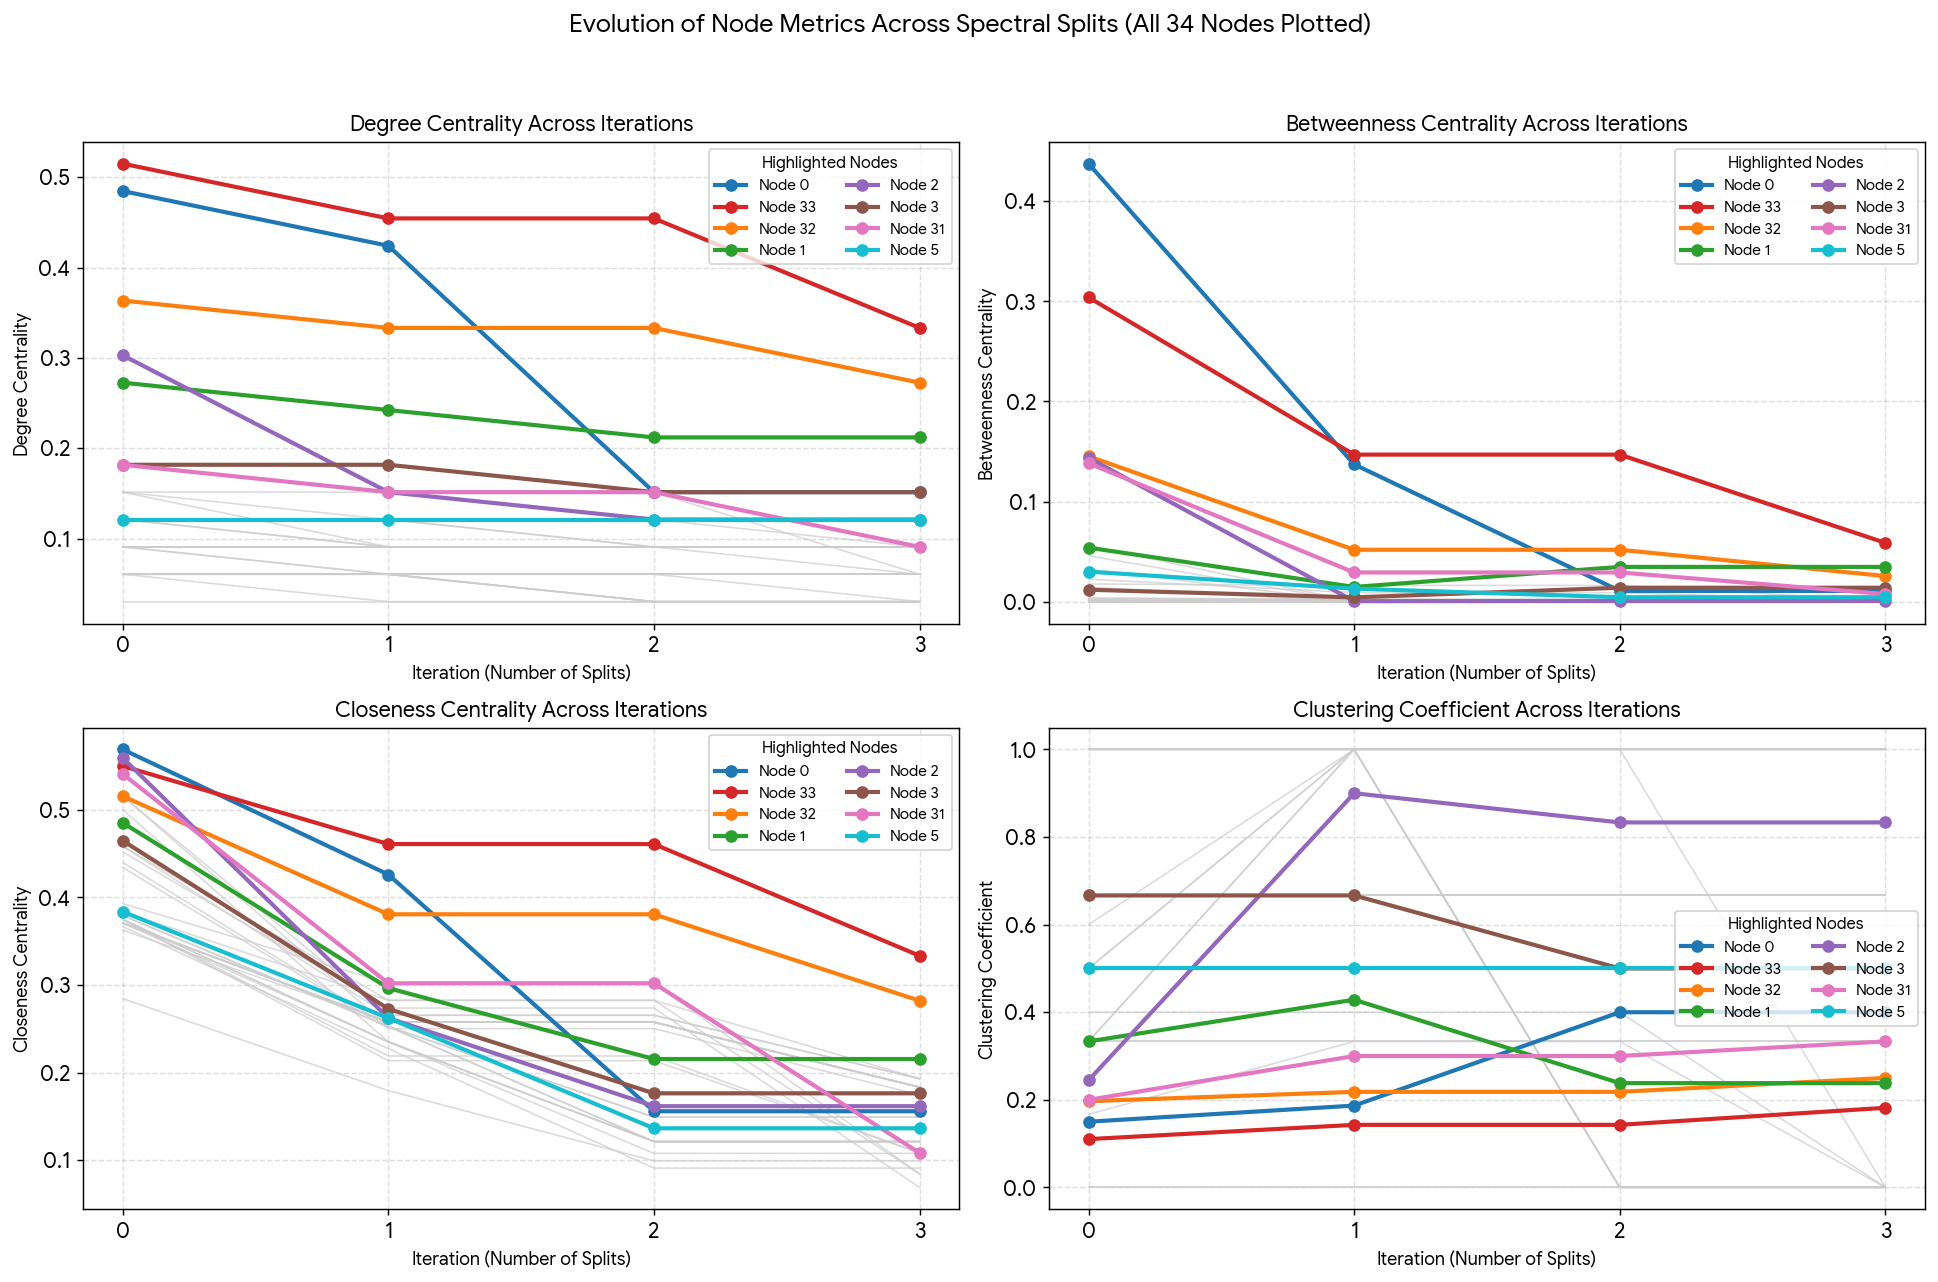

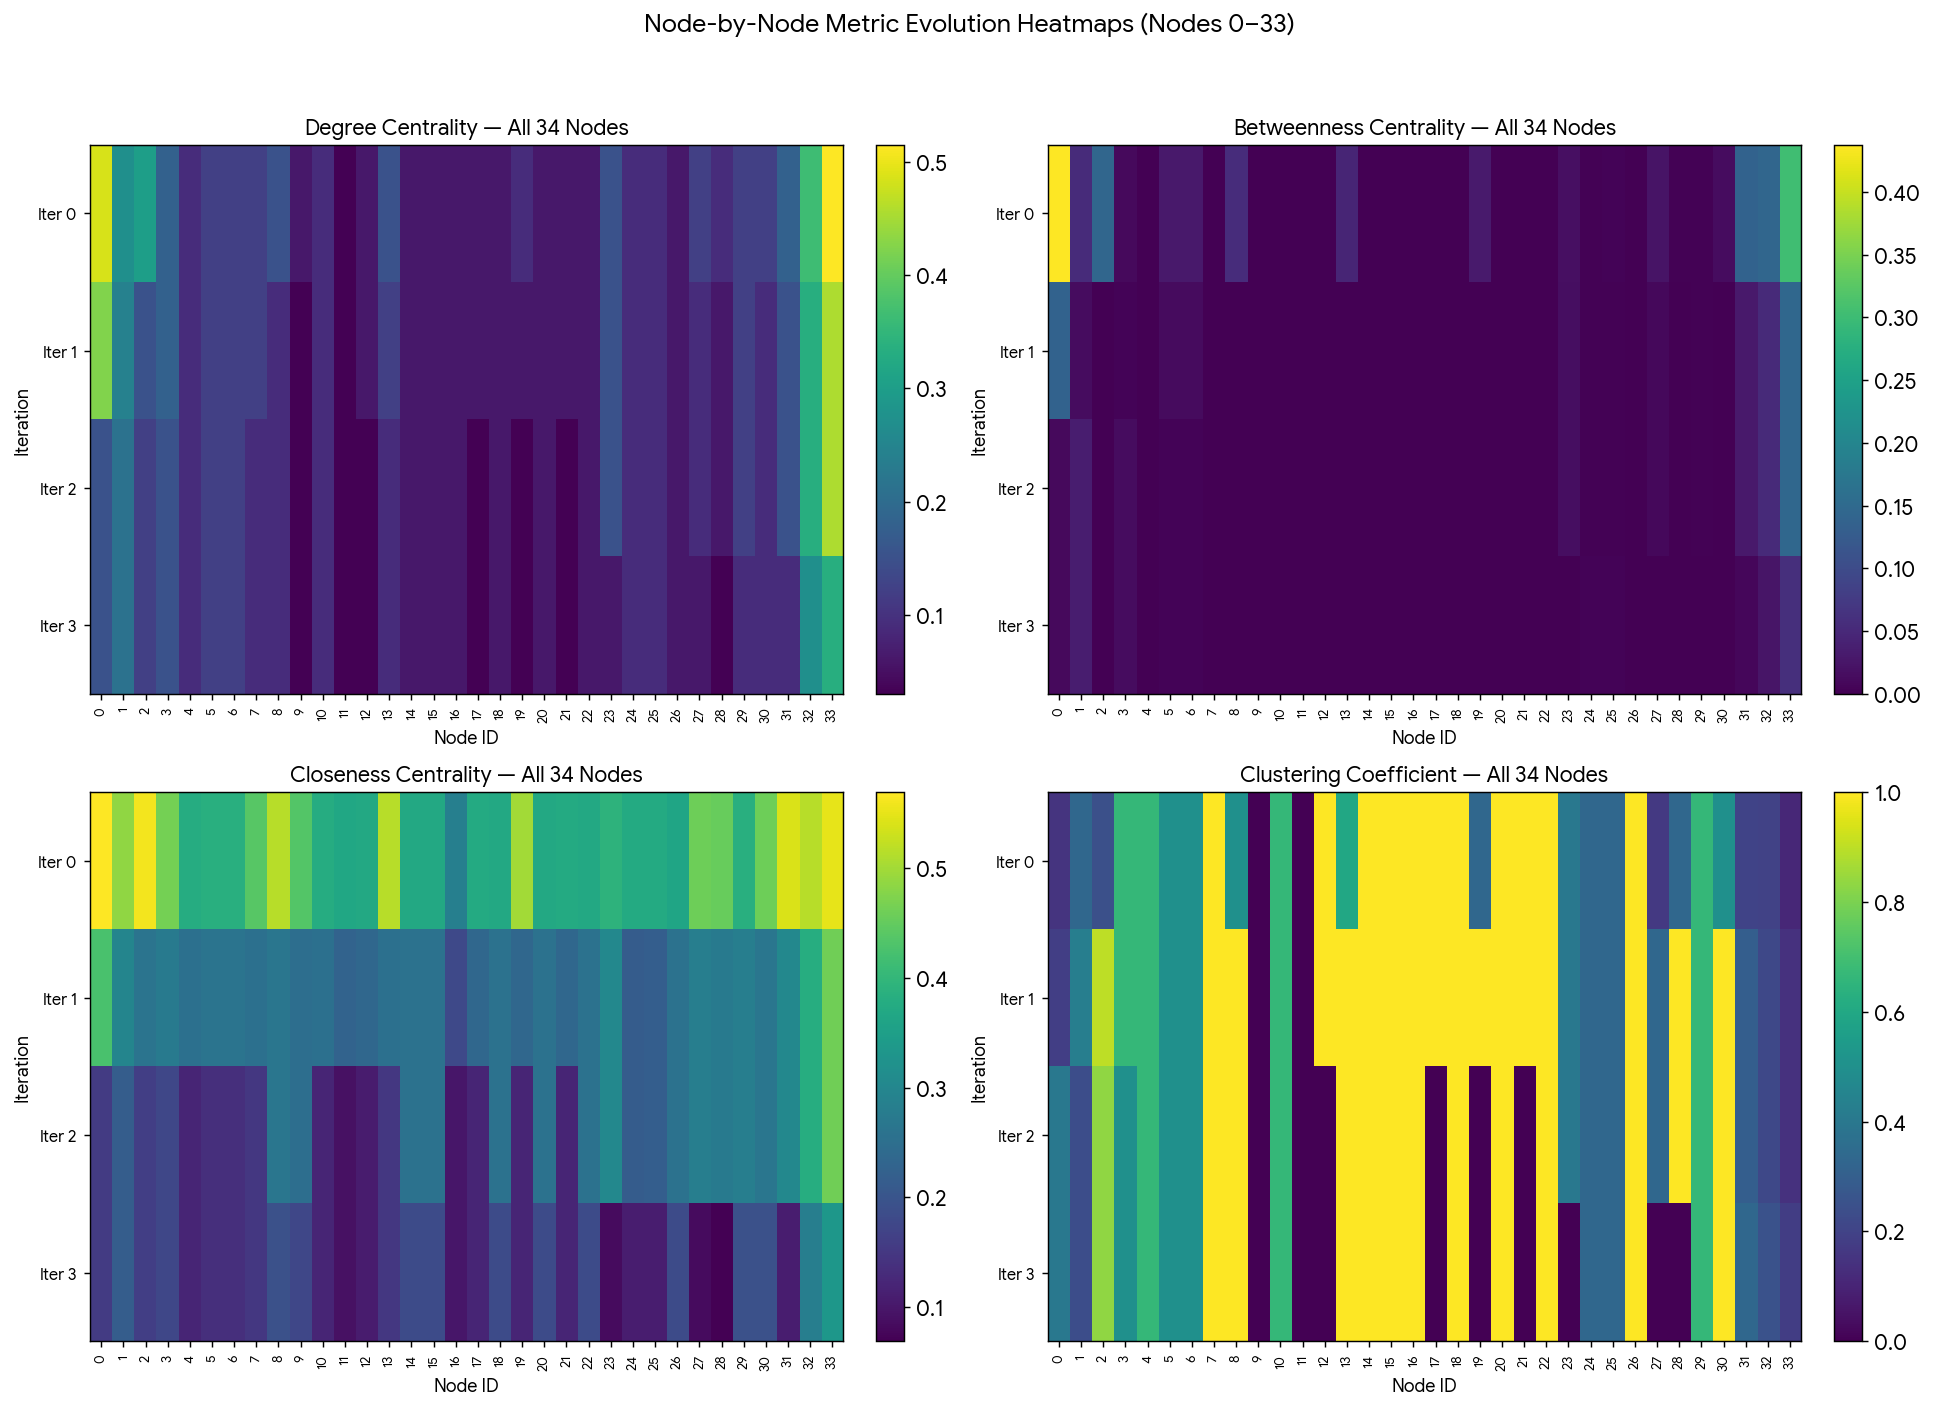

In [5]:
iterations = [step["iteration"] for step in history]
highlight_nodes = [0, 33, 32, 1, 2, 3, 31, 5]
highlight_colors = {
    0: "#1f77b4",
    33: "#d62728",
    32: "#ff7f0e",
    1: "#2ca02c",
    2: "#9467bd",
    3: "#8c564b",
    31: "#e377c2",
    5: "#17becf",
}

# 1. Line plots for all 34 nodes (with key nodes highlighted)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for ax, (metric_name, hist_dict) in zip(axes, metrics_all.items()):
    # Plot all remaining nodes in subtle grey
    for u in nodes:
        if u not in highlight_nodes:
            vals = [hist_dict[it][u] for it in iterations]
            ax.plot(iterations, vals, color="#CCCCCC", linewidth=0.9, alpha=0.7)

    # Highlight key nodes
    for u in highlight_nodes:
        vals = [hist_dict[it][u] for it in iterations]
        ax.plot(
            iterations, vals,
            color=highlight_colors[u],
            marker="o",
            linewidth=2.3,
            markersize=6,
            label=f"Node {u}"
        )

    ax.set_title(f"{metric_name} Across Iterations", fontsize=12, fontweight="bold")
    ax.set_xlabel("Iteration (Number of Splits)", fontsize=10)
    ax.set_ylabel(metric_name, fontsize=10)
    ax.set_xticks(iterations)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(title="Highlighted Nodes", fontsize=8.5, title_fontsize=9, ncol=2, loc="best")

plt.suptitle("Evolution of Node Metrics Across Spectral Splits (All 34 Nodes Plotted)", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# 2. Heatmaps showing exact trajectories for EVERY single node (0 to 33)
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for ax, (metric_name, hist_dict) in zip(axes, metrics_all.items()):
    mat = np.array([[hist_dict[it][u] for u in nodes] for it in iterations])
    im = ax.imshow(mat, aspect="auto", cmap="viridis")
    ax.set_title(f"{metric_name} — All 34 Nodes", fontsize=12, fontweight="bold")
    ax.set_xlabel("Node ID", fontsize=10)
    ax.set_ylabel("Iteration", fontsize=10)
    ax.set_xticks(range(n))
    ax.set_xticklabels(nodes, fontsize=7.5, rotation=90)
    ax.set_yticks(range(len(iterations)))
    ax.set_yticklabels([f"Iter {it}" for it in iterations], fontsize=9)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("Node-by-Node Metric Evolution Heatmaps (Nodes 0–33)", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 7. Task 5: Discussion & Insights

### 1. Community Detection Results
- **First Split (Iteration 1, $Q = 0.3715$):** Spectral bipartition cleanly divides the 34-member club into two factions of sizes **16** and **18**, achieving **97.06% agreement (33/34 nodes)** with Zachary's recorded ground-truth split (only Node 8, a well-known border node with ties to both leaders, is placed on the opposite side).
- **Further Splits (Iterations 2 & 3, $Q = 0.3934$):** Recursive bisection subdivides Mr. Hi's faction into two sub-communities (sizes 7 and 9, $\Delta Q = +0.0012$) and the Officer's faction into two sub-communities (sizes 12 and 6, $\Delta Q = +0.0207$). After 3 splits (4 communities total), every remaining community has $\lambda_1^{(C)} \le 0$ (or $\Delta Q \le 0$), so the algorithm terminates naturally.

### 2. Which Nodes Consistently Remain Central?
- **Primary Leaders — Node 33 (Officer) and Node 0 (Mr. Hi):** Across all iterations, **Node 33** remains the highest-degree and highest-betweenness hub in the entire network, even after its faction splits at Iteration 3. **Node 0** stays the dominant hub of its sub-community (alongside **Node 32** in the Officer's core and **Node 1 / Node 2** in the second Mr. Hi sub-community).
- **Local Sub-Community Hubs — Nodes 32, 1, 2, 3, and 31:** Once the two main factions split further, nodes that sit deep inside dense sub-groups (such as **Node 32** with Node 33, **Nodes 1, 2, 3** in the 9-node sub-group, and **Node 31** in the 6-node sub-group) emerge as strong local hubs with high intra-community degree and betweenness.

### 3. How Community Structure Influences Each Metric
- **Degree Centrality:** Drops monotonically as inter-community edges are removed. Nodes with many cross-community ties (e.g., **Node 0** losing connections to Nodes 1, 2, 3, 7, 13 at Iteration 2, or **Node 2** losing links across both factions) experience sharp drops, whereas peripheral nodes embedded strictly inside one clique retain almost all of their degree.
- **Betweenness Centrality:** This metric is the most sensitive to community boundaries. **Bridge nodes** (like **Node 0**, **Node 2**, **Node 31**, **Node 8**, and **Node 19**) initially carry huge betweenness because shortest paths between rival factions must pass through them. The moment inter-community edges are cut, those cross-faction paths disappear and bridge betweenness collapses dramatically; only within-community hubs (**Nodes 33, 0, 1, 31**) retain meaningful betweenness.
- **Closeness Centrality:** Decreases across all nodes with every split. Because `nx.closeness_centrality` scales by the fraction of reachable nodes in disconnected graphs, splitting the network into smaller isolated components shrinks each node's reachable neighborhood and lowers its closeness score uniformly within each community.
- **Clustering Coefficient:** Unlike global centrality measures, clustering is a **local** property and behaves differently: for nodes embedded inside tightly-knit triangles (such as **Nodes 4, 5, 6, 10, 16** or **Nodes 14, 15, 18, 20, 22**), clustering stays high—or even **increases**—after cross-community edges are removed, because removing non-triadic bridge edges increases the density of triangles among their remaining neighbors. Conversely, bridge nodes whose triangles spanned across communities see their clustering drop.

---

## References
1. Newman, M. E. J. (2006). *Modularity and community structure in networks*. Proceedings of the National Academy of Sciences (PNAS), 103(23), 8577–8582.
2. Zachary, W. W. (1977). *An information flow model for conflict and fission in small groups*. Journal of Anthropological Research, 33(4), 452–473.
